In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Display all columns when inspecting datasets
pd.set_option("display.max_columns", None)

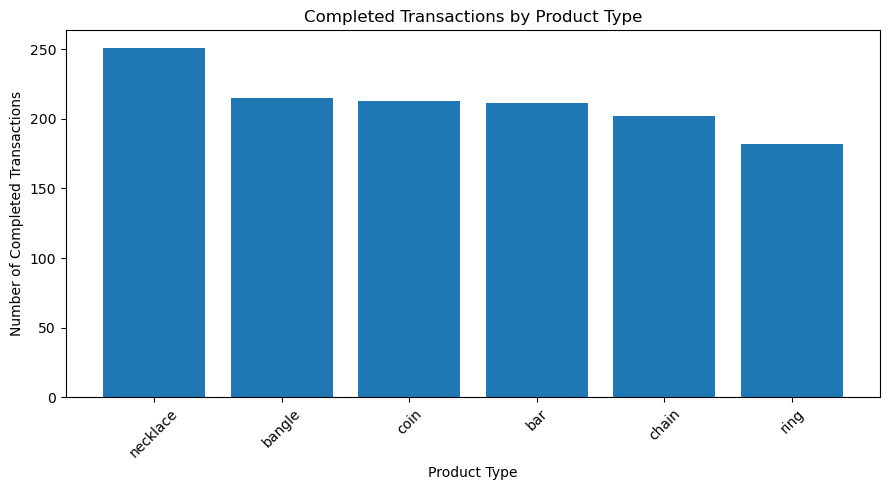

In [4]:
# Sort products by completed transaction count
product_sales_sorted = product_sales.sort_values(
    by="completed_transactions",
    ascending=False
)

# Create bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    product_sales_sorted["product_type"],
    product_sales_sorted["completed_transactions"]
)

plt.title("Completed Transactions by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Number of Completed Transactions")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

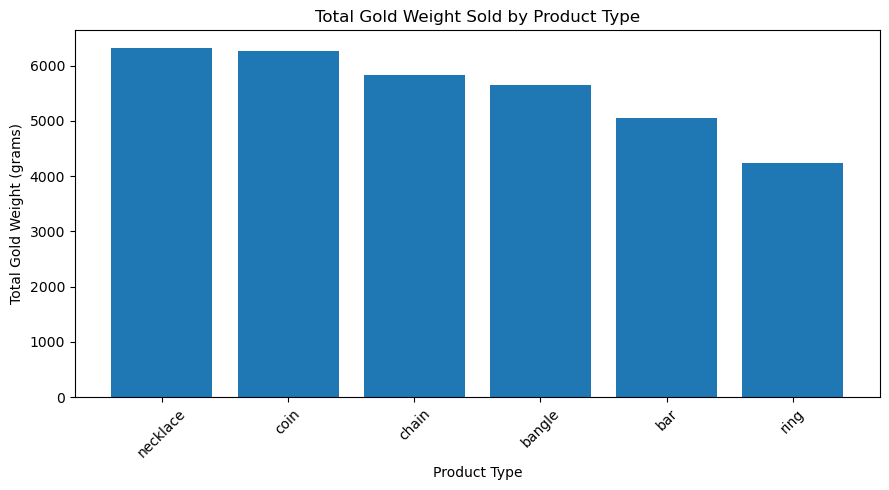

In [5]:
# Sort products by total gold weight
product_weight_sorted = product_sales.sort_values(
    by="total_weight_grams",
    ascending=False
)

# Create bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    product_weight_sorted["product_type"],
    product_weight_sorted["total_weight_grams"]
)

plt.title("Total Gold Weight Sold by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Total Gold Weight (grams)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

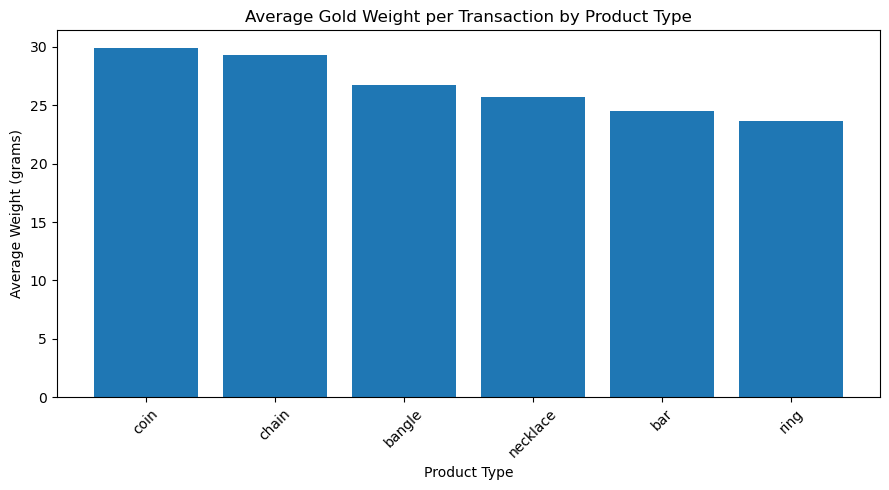

In [6]:
# Sort products by average transaction weight
product_avg_weight = product_sales.sort_values(
    by="average_weight_grams",
    ascending=False
)

# Create bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    product_avg_weight["product_type"],
    product_avg_weight["average_weight_grams"]
)

plt.title("Average Gold Weight per Transaction by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Average Weight (grams)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

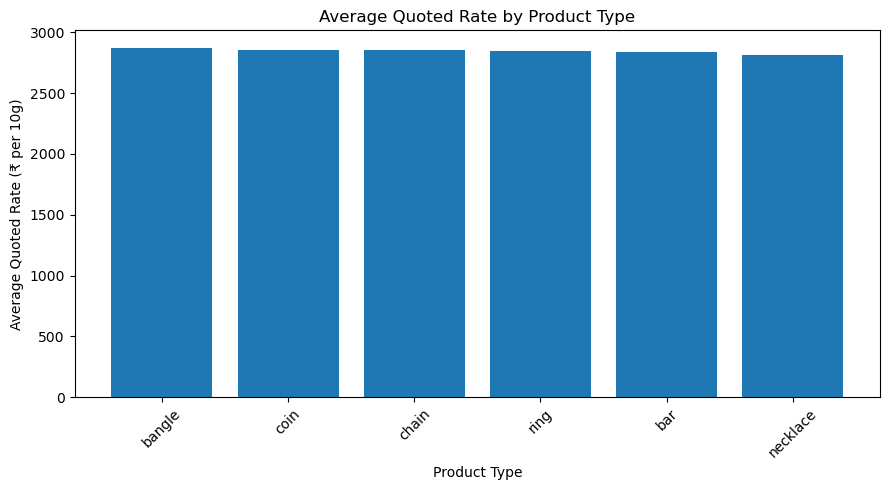

In [7]:
# Sort products by average quoted rate
product_rate_sorted = product_sales.sort_values(
    by="average_quoted_rate",
    ascending=False
)

# Create bar chart
plt.figure(figsize=(9, 5))

plt.bar(
    product_rate_sorted["product_type"],
    product_rate_sorted["average_quoted_rate"]
)

plt.title("Average Quoted Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Average Quoted Rate (₹ per 10g)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
monthly_prices = pd.read_csv(
    "../outputs/analytics/price_monthly_summary/csv/data.csv"
)

display(monthly_prices)

,year_month,available_price_days,average_price,highest_price,lowest_price,price_stddev,average_daily_change_pct,daily_return_volatility_pct,monthly_net_price_change
0,2025-01,30,2699.921667,2760.88,2659.09,23.680581,0.093991,0.677131,71.69
1,2025-02,25,2754.482000,2800.20,2714.11,23.054303,0.001463,0.615255,-0.24
2,2025-03,31,2791.524194,2882.69,2686.53,64.919375,0.169517,0.605888,145.62
3,2025-04,30,2864.989333,2900.79,2810.73,19.950948,-0.026706,0.572701,-24.31
4,2025-05,31,2795.398387,2855.79,2734.55,41.056150,-0.129111,0.524001,-113.09
5,2025-06,30,2796.213000,2840.78,2749.75,23.779997,0.051702,0.717144,40.73
6,2025-07,31,2891.915484,3032.19,2763.06,85.122882,0.282119,0.460219,252.70
7,2025-08,31,3221.310000,3341.51,3047.92,92.903339,0.314653,0.484699,308.99
8,2025-09,30,3439.191333,3486.45,3366.51,29.747109,0.127021,0.501594,128.43
9,2025-10,31,3533.328065,3602.11,3444.92,45.179512,0.106050,0.487833,114.62


In [9]:
monthly_prices.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   year_month                   12 non-null     object 
 1   available_price_days         12 non-null     int64  
 2   average_price                12 non-null     float64
 3   highest_price                12 non-null     float64
 4   lowest_price                 12 non-null     float64
 5   price_stddev                 12 non-null     float64
 6   average_daily_change_pct     12 non-null     float64
 7   daily_return_volatility_pct  12 non-null     float64
 8   monthly_net_price_change     12 non-null     float64
dtypes: float64(7), int64(1), object(1)
memory usage: 996.0+ bytes


In [1]:
from pathlib import Path
import pandas as pd
import json

# Root analytics directory
ANALYTICS_DIR = Path("../outputs/analytics")

# Store metadata for all CSV files
csv_metadata = {}

# Find every CSV file recursively
csv_files = list(ANALYTICS_DIR.rglob("*.csv"))

print(f"Total CSV files found: {len(csv_files)}")

for file_path in csv_files:

    # Load CSV
    df = pd.read_csv(file_path)

    # Relative path from analytics folder
    relative_path = file_path.relative_to(ANALYTICS_DIR)

    # Collect metadata
    csv_metadata[str(relative_path)] = {
        "file_name": file_path.name,
        "rows": len(df),
        "columns_count": len(df.columns),
        "columns": list(df.columns),
        "data_types": df.dtypes.astype(str).to_dict(),
        "null_counts": df.isnull().sum().to_dict(),
        "sample_records": df.head(5).to_dict(orient="records"),
        "numeric_summary": df.describe().to_dict()
    }

    print(f"Processed: {relative_path}")

print("\nMetadata collection completed!")

Total CSV files found: 31
Processed: completed_sales_by_product\csv\data.csv
Processed: completed_sales_by_purity\csv\data.csv
Processed: completed_sales_by_region\csv\data.csv
Processed: completed_transactions_with_estimated_values\csv\data.csv
Processed: event_category_price_movement\csv\data.csv
Processed: event_price_windows\csv\data.csv
Processed: high_value_concentration\csv\data.csv
Processed: high_value_threshold\csv\data.csv
Processed: high_value_transactions\csv\data.csv
Processed: making_charge_comparison_detail\csv\data.csv
Processed: making_charge_comparison_summary\csv\data.csv
Processed: market_events_by_month\csv\data.csv
Processed: market_event_type_summary\csv\data.csv
Processed: monthly_product_mix\csv\data.csv
Processed: monthly_sales_trends\csv\data.csv
Processed: price_daily_trends\csv\data.csv
Processed: price_monthly_summary\csv\data.csv
Processed: price_movement_rankings\csv\data.csv
Processed: price_period_extremes\csv\data.csv
Processed: price_vs_sales_activi

In [2]:
metadata_file = Path("../outputs/csv_metadata.json")

metadata_file.parent.mkdir(parents=True, exist_ok=True)

with open(metadata_file, "w", encoding="utf-8") as file:
    json.dump(csv_metadata, file, indent=4, default=str)

print(f"Metadata saved to: {metadata_file.resolve()}")

Metadata saved to: C:\Users\ipran\Documents\demo\gold-market-explorer\outputs\csv_metadata.json


In [3]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.style.use("ggplot")

# Locate the project root
if Path("outputs/analytics").exists():
    PROJECT_ROOT = Path(".")
elif Path("../outputs/analytics").exists():
    PROJECT_ROOT = Path("..")
else:
    raise FileNotFoundError("Could not locate outputs/analytics")

ANALYTICS_DIR = PROJECT_ROOT / "outputs" / "analytics"

# Consistent chart settings
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10

print("Analytics directory:", ANALYTICS_DIR)

Analytics directory: ..\outputs\analytics


In [4]:
def load_output(name):
    file_path = ANALYTICS_DIR / name / "csv" / "data.csv"

    if not file_path.exists():
        raise FileNotFoundError(f"Output not found: {file_path}")

    df = pd.read_csv(file_path)

    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

    return df


def find_column(df, *candidates):
    """
    Find the first matching column from a list of possible names.
    """
    for candidate in candidates:
        if candidate in df.columns:
            return candidate

    raise KeyError(
        f"None of these columns were found: {candidates}\n"
        f"Available columns: {df.columns.tolist()}"
    )


def format_inr(value, position=None):
    return f"₹{value:,.0f}"

In [5]:
price_daily = load_output("price_daily_trends")
price_monthly = load_output("price_monthly_summary")

transaction_status = load_output("transaction_status_summary")
product_contribution = load_output("product_value_contribution")

regional_performance = load_output("regional_performance")
regional_completion = load_output("regional_completion_rates")

making_charge = load_output("making_charge_comparison_summary")
quoted_comparison = load_output("quoted_vs_market_price_summary")

high_value = load_output("high_value_concentration")

price_sales = load_output("price_vs_sales_activity")

event_movement = load_output("event_category_price_movement")

price_daily_trends: 361 rows, 11 columns
price_monthly_summary: 12 rows, 9 columns
transaction_status_summary: 4 rows, 2 columns
product_value_contribution: 6 rows, 8 columns
regional_performance: 8 rows, 8 columns
regional_completion_rates: 8 rows, 11 columns
making_charge_comparison_summary: 7 rows, 5 columns
quoted_vs_market_price_summary: 3 rows, 6 columns
high_value_concentration: 48 rows, 6 columns
price_vs_sales_activity: 12 rows, 5 columns
event_category_price_movement: 5 rows, 6 columns


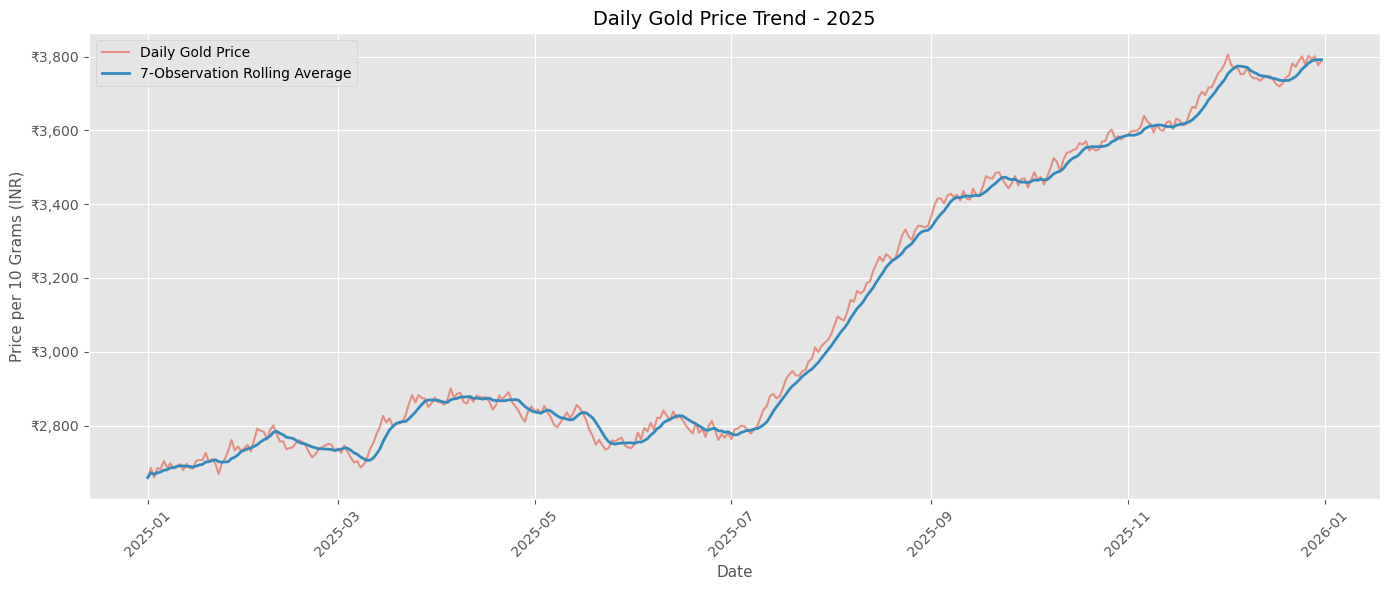

In [6]:
price_daily["date"] = pd.to_datetime(price_daily["price_date"])

price_daily = price_daily.sort_values("date")

rolling_column = "rolling_avg_7_observations"

plt.figure(figsize=(14, 6))

plt.plot(
    price_daily["date"],
    price_daily["price_per_10g_inr"],
    label="Daily Gold Price",
    alpha=0.55
)

plt.plot(
    price_daily["date"],
    price_daily[rolling_column],
    label="7-Observation Rolling Average",
    linewidth=2
)

plt.title("Daily Gold Price Trend - 2025")
plt.xlabel("Date")
plt.ylabel("Price per 10 Grams (INR)")

plt.gca().yaxis.set_major_formatter(
    mtick.FuncFormatter(format_inr)
)

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

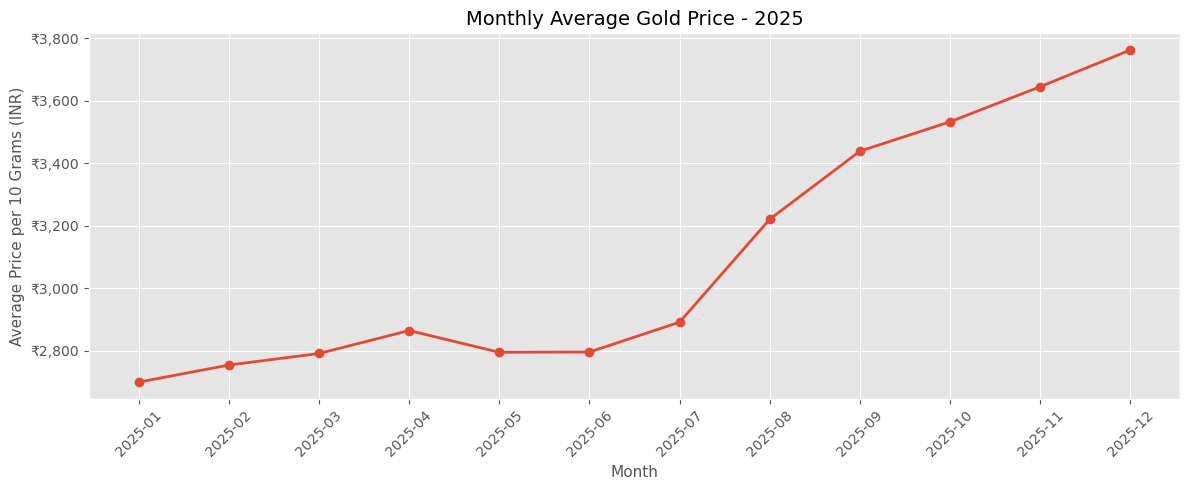

In [7]:
price_monthly = price_monthly.sort_values("year_month")

plt.figure(figsize=(12, 5))

plt.plot(
    price_monthly["year_month"],
    price_monthly["average_price"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Average Gold Price - 2025")
plt.xlabel("Month")
plt.ylabel("Average Price per 10 Grams (INR)")

plt.gca().yaxis.set_major_formatter(
    mtick.FuncFormatter(format_inr)
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

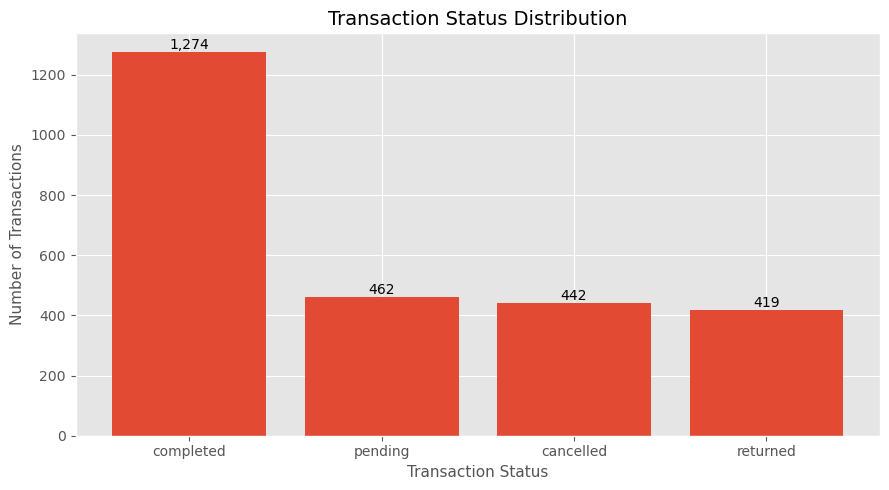

In [8]:
transaction_status = transaction_status.sort_values(
    "transaction_count",
    ascending=False
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    transaction_status["transaction_status"],
    transaction_status["transaction_count"]
)

plt.title("Transaction Status Distribution")
plt.xlabel("Transaction Status")
plt.ylabel("Number of Transactions")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

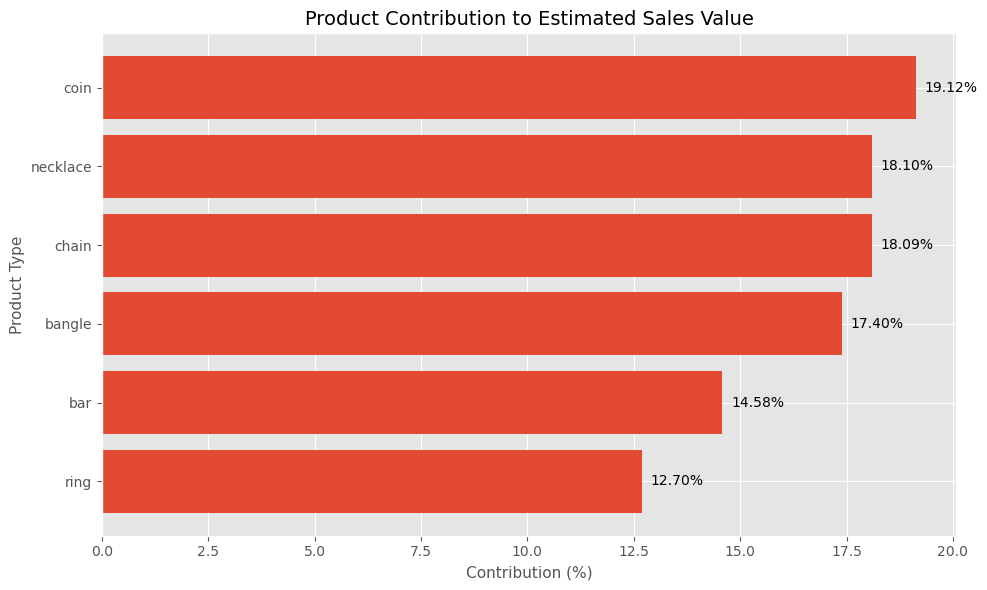

In [9]:
contribution_column = find_column(
    product_contribution,
    "value_contribution_pct",
    "contribution_pct",
    "estimated_value_contribution_pct",
    "value_contribution_percentage"
)

product_contribution = product_contribution.sort_values(
    contribution_column
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    product_contribution["product_type"],
    product_contribution[contribution_column]
)

plt.title("Product Contribution to Estimated Sales Value")
plt.xlabel("Contribution (%)")
plt.ylabel("Product Type")

for bar in bars:
    plt.text(
        bar.get_width() + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

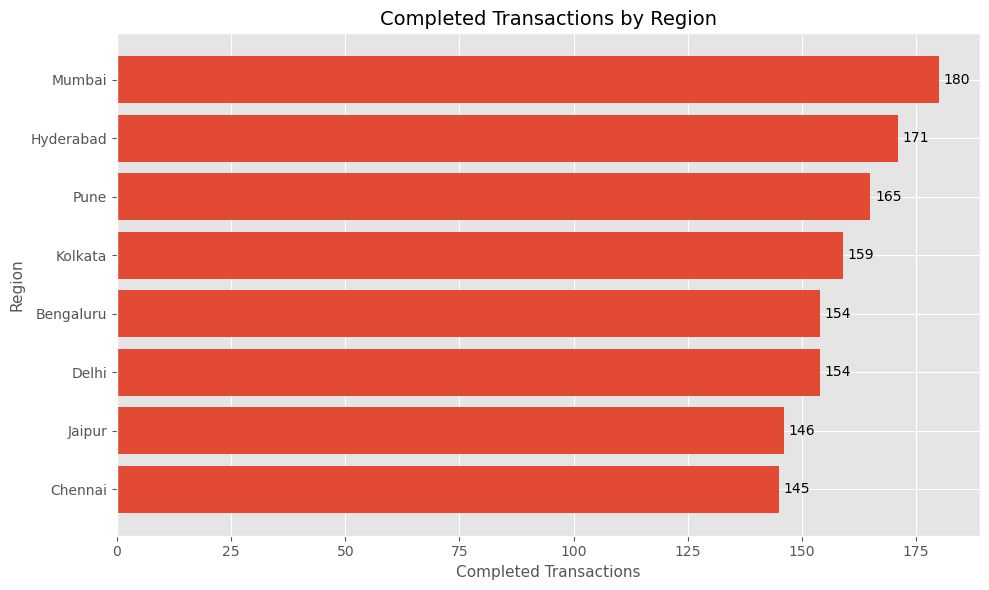

In [10]:
regional_performance = regional_performance.sort_values(
    "completed_transactions"
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    regional_performance["region_name"],
    regional_performance["completed_transactions"]
)

plt.title("Completed Transactions by Region")
plt.xlabel("Completed Transactions")
plt.ylabel("Region")

for bar in bars:
    plt.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width())}",
        va="center"
    )

plt.tight_layout()
plt.show()

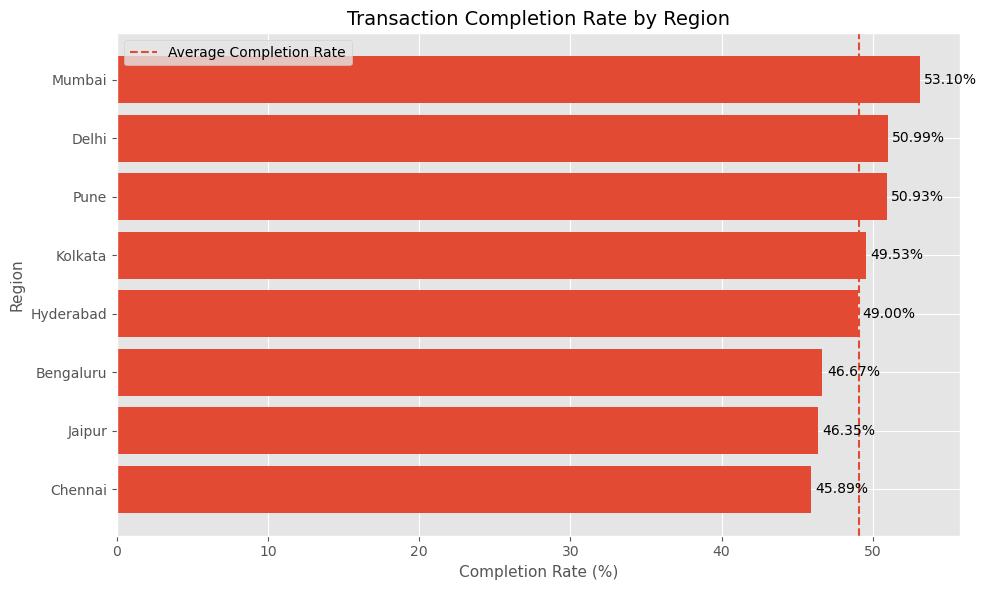

In [11]:
regional_completion = regional_completion.sort_values(
    "completion_rate_pct"
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    regional_completion["region_name"],
    regional_completion["completion_rate_pct"]
)

plt.title("Transaction Completion Rate by Region")
plt.xlabel("Completion Rate (%)")
plt.ylabel("Region")

plt.axvline(
    regional_completion["completion_rate_pct"].mean(),
    linestyle="--",
    label="Average Completion Rate"
)

for bar in bars:
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center"
    )

plt.legend()
plt.tight_layout()
plt.show()

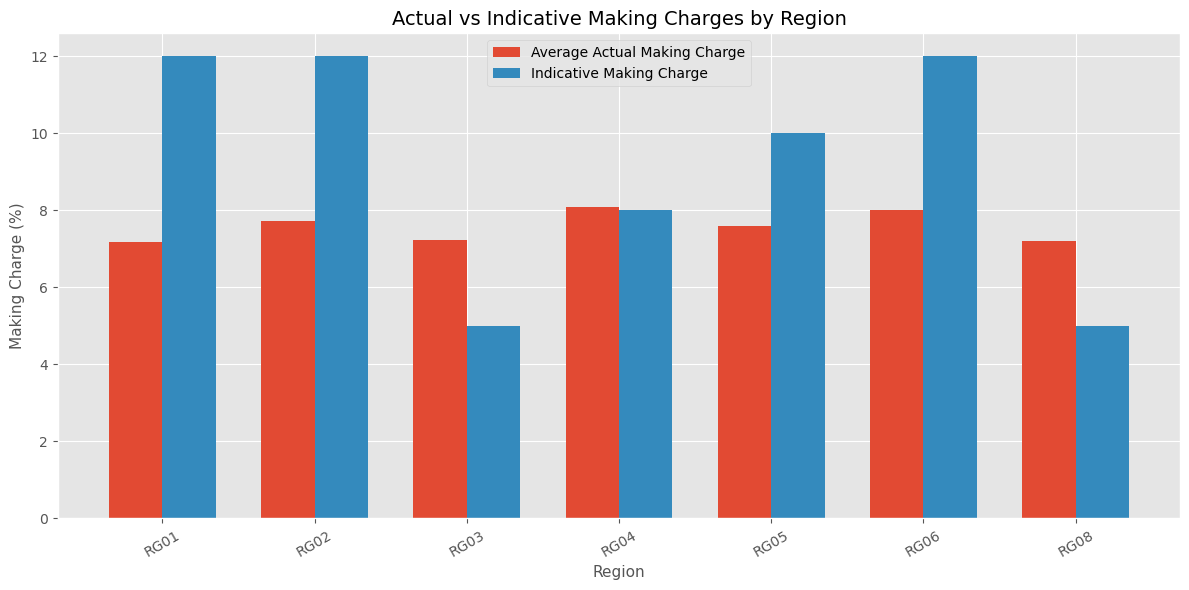

In [12]:
actual_column = find_column(
    making_charge,
    "average_transaction_making_charge_pct",
    "average_actual_making_charge_pct",
    "average_transaction_charge_pct",
    "average_making_charge_pct"
)

indicative_column = find_column(
    making_charge,
    "indicative_making_charge_pct",
    "regional_making_charge_pct",
    "indicative_charge_pct"
)

region_column = find_column(
    making_charge,
    "region_name",
    "region_id"
)

making_charge = making_charge.sort_values(region_column)

x = range(len(making_charge))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    [i - width / 2 for i in x],
    making_charge[actual_column],
    width,
    label="Average Actual Making Charge"
)

plt.bar(
    [i + width / 2 for i in x],
    making_charge[indicative_column],
    width,
    label="Indicative Making Charge"
)

plt.title("Actual vs Indicative Making Charges by Region")
plt.xlabel("Region")
plt.ylabel("Making Charge (%)")

plt.xticks(
    list(x),
    making_charge[region_column],
    rotation=30
)

plt.legend()
plt.tight_layout()
plt.show()

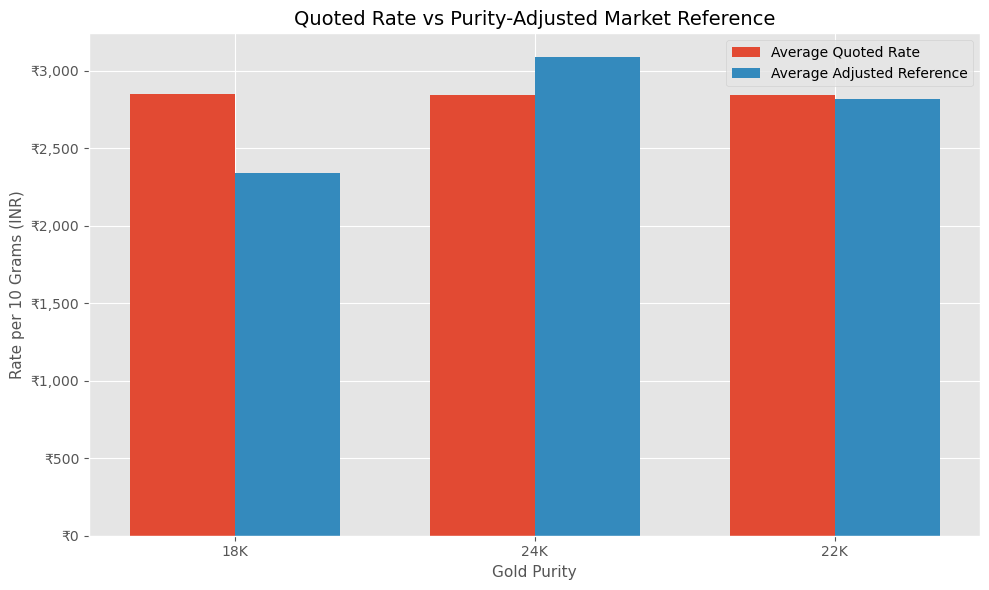

In [13]:
quoted_comparison = quoted_comparison.set_index("purity")

x = range(len(quoted_comparison))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    [i - width / 2 for i in x],
    quoted_comparison["average_quoted_rate"],
    width,
    label="Average Quoted Rate"
)

plt.bar(
    [i + width / 2 for i in x],
    quoted_comparison["average_adjusted_reference"],
    width,
    label="Average Adjusted Reference"
)

plt.title("Quoted Rate vs Purity-Adjusted Market Reference")
plt.xlabel("Gold Purity")
plt.ylabel("Rate per 10 Grams (INR)")

plt.xticks(
    list(x),
    quoted_comparison.index
)

plt.gca().yaxis.set_major_formatter(
    mtick.FuncFormatter(format_inr)
)

plt.legend()
plt.tight_layout()
plt.show()

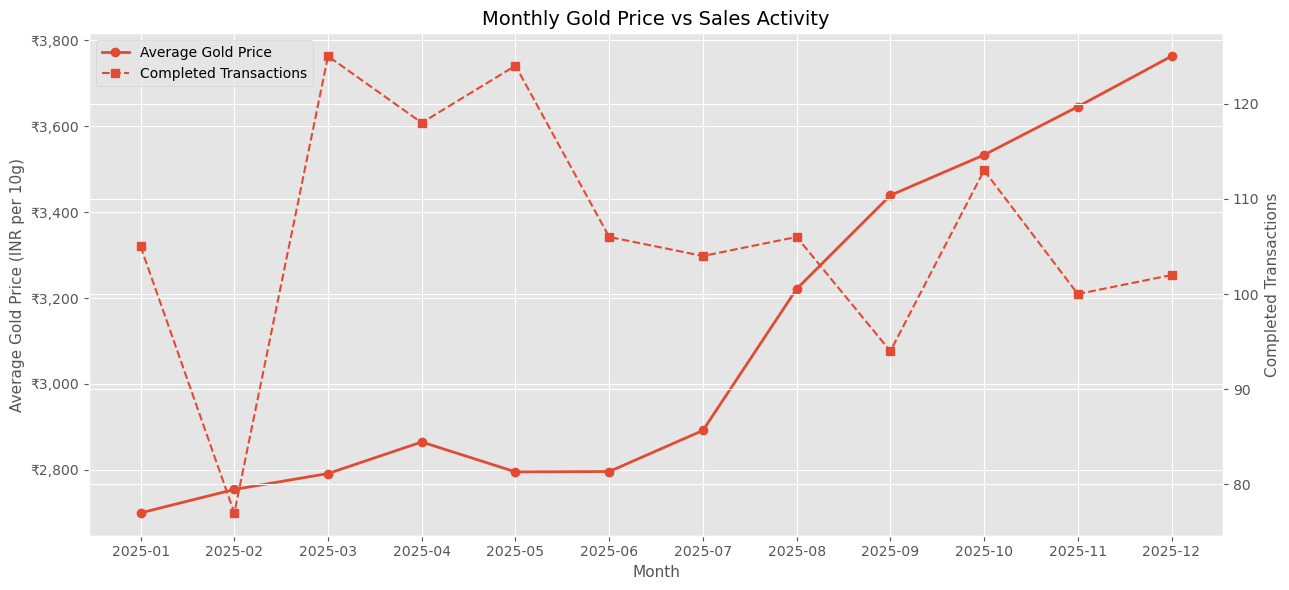

In [16]:
price_sales = price_sales.sort_values("year_month")

fig, ax1 = plt.subplots(figsize=(13, 6))

ax1.plot(
    price_sales["year_month"],
    price_sales["monthly_average_gold_price"],
    marker="o",
    linewidth=2,
    label="Average Gold Price"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Average Gold Price (INR per 10g)")

ax1.yaxis.set_major_formatter(
    mtick.FuncFormatter(format_inr)
)

ax2 = ax1.twinx()

ax2.plot(
    price_sales["year_month"],
    price_sales["completed_transactions"],
    marker="s",
    linestyle="--",
    label="Completed Transactions"
)

ax2.set_ylabel("Completed Transactions")

plt.title("Monthly Gold Price vs Sales Activity")

plt.xticks(rotation=45)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left"
)

plt.tight_layout()
plt.show()

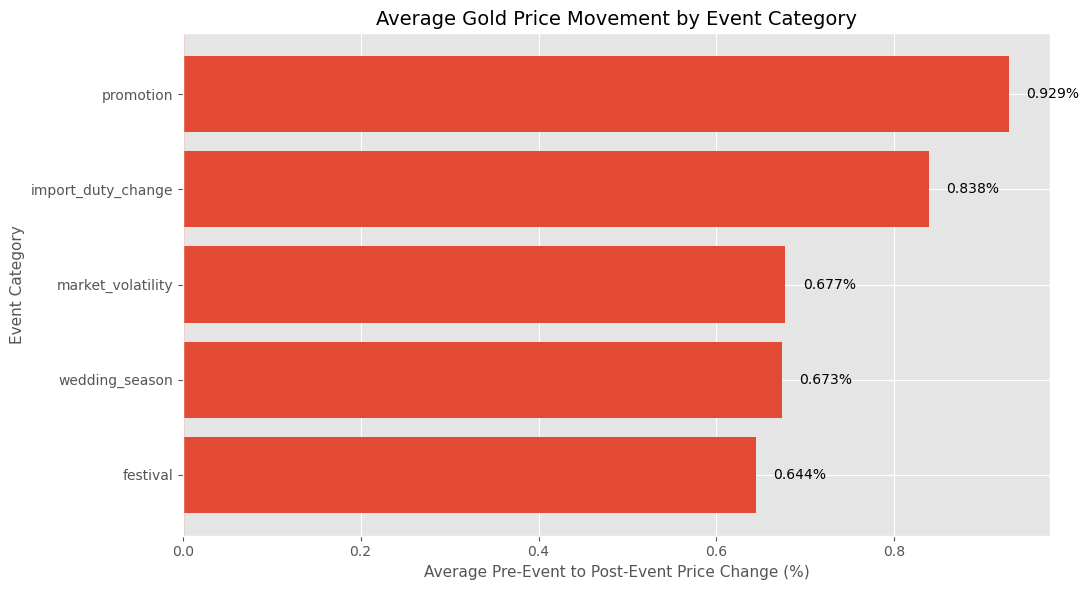

In [17]:
event_category_column = find_column(
    event_movement,
    "event_category",
    "event_type"
)

movement_column = find_column(
    event_movement,
    "average_pre_post_change_pct",
    "average_pre_post_price_change_pct",
    "average_price_change_pct",
    "average_pre_post_pct_change"
)

event_movement = event_movement.sort_values(
    movement_column
)

plt.figure(figsize=(11, 6))

bars = plt.barh(
    event_movement[event_category_column],
    event_movement[movement_column]
)

plt.title("Average Gold Price Movement by Event Category")
plt.xlabel("Average Pre-Event to Post-Event Price Change (%)")
plt.ylabel("Event Category")

plt.axvline(0, linewidth=1)

for bar in bars:
    plt.text(
        bar.get_width() + 0.02,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.3f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

In [18]:
monthly_product_mix = load_output("monthly_product_mix")

print(monthly_product_mix.columns.tolist())
display(monthly_product_mix.head())

monthly_product_mix: 72 rows, 6 columns
['year_month', 'product_type', 'completed_transactions', 'total_weight_grams', 'monthly_transaction_total', 'product_mix_pct']


,year_month,product_type,completed_transactions,total_weight_grams,monthly_transaction_total,product_mix_pct
0,2025-01,bangle,20,580.0,105,19.047619
1,2025-01,bar,11,222.0,105,10.476190
2,2025-01,chain,19,726.0,105,18.095238
3,2025-01,coin,21,850.0,105,20.000000
4,2025-01,necklace,17,498.0,105,16.190476


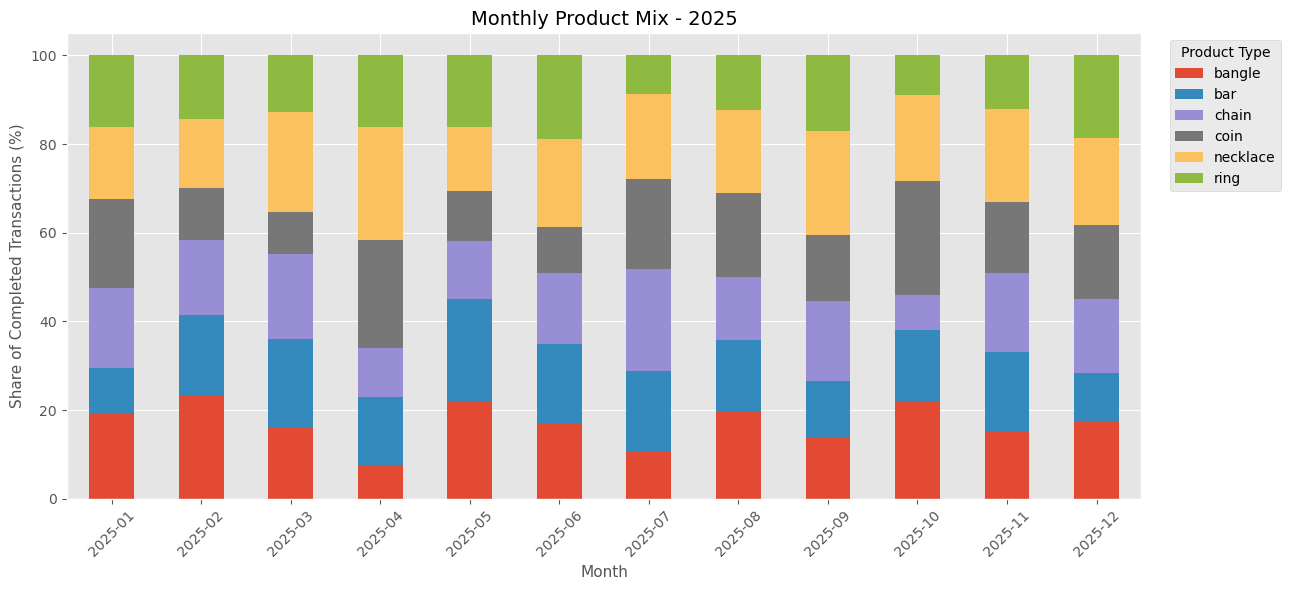

In [19]:
# Replace these names if your exported schema differs
month_col = "year_month"
product_col = "product_type"
count_col = "completed_transactions"

# Convert to month-by-product table
product_pivot = monthly_product_mix.pivot(
    index=month_col,
    columns=product_col,
    values=count_col
).fillna(0)

# Convert counts into monthly percentages
product_percentage = (
    product_pivot.div(product_pivot.sum(axis=1), axis=0) * 100
)

product_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(13, 6)
)

plt.title("Monthly Product Mix - 2025")
plt.xlabel("Month")
plt.ylabel("Share of Completed Transactions (%)")
plt.xticks(rotation=45)
plt.legend(title="Product Type", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [20]:
regional_status = load_output("regional_transaction_status")

print(regional_status.columns.tolist())
display(regional_status.head())

regional_transaction_status: 33 rows, 3 columns
['region_id', 'transaction_status', 'transaction_count']


,region_id,transaction_status,transaction_count
0,RG03,cancelled,47
1,RG02,completed,180
2,RG02,cancelled,49
3,RG06,returned,57
4,RG06,completed,154


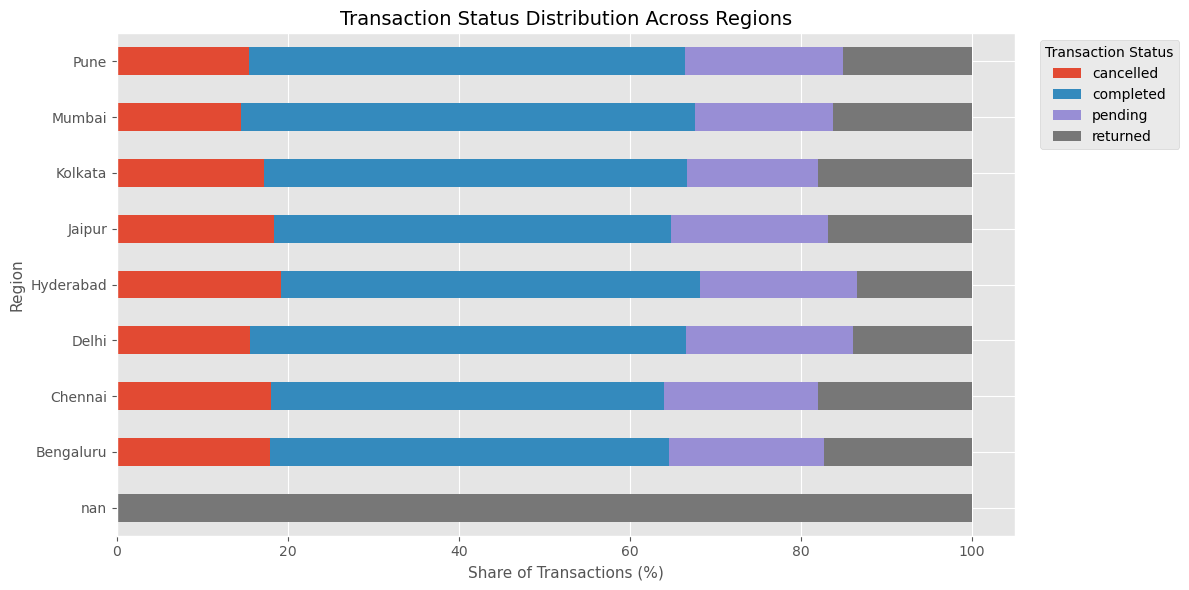

In [21]:
# Load the region reference names from the regional performance output
region_names = regional_performance[
    ["region_id", "region_name"]
].drop_duplicates()

regional_status = regional_status.merge(
    region_names,
    on="region_id",
    how="left"
)

status_pivot = regional_status.pivot(
    index="region_name",
    columns="transaction_status",
    values="transaction_count"
).fillna(0)

# Convert transaction counts into regional percentages
status_percentage = (
    status_pivot.div(status_pivot.sum(axis=1), axis=0) * 100
)

status_percentage.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Transaction Status Distribution Across Regions")
plt.xlabel("Share of Transactions (%)")
plt.ylabel("Region")
plt.legend(title="Transaction Status", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()